# Proyecto Fase 3: Predicción y Análisis de la Deserción Escolar en el Instituto Tecnológico de Tláhuac III
**Metodología:** CRISP-DM  
**Objetivo:** Limpiar los datos académicos y socioeconómicos estudiantiles, realizar un análisis exploratorio (EDA) y entrenar un modelo de clasificación supervisada para identificar estudiantes en riesgo de deserción escolar.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, classification_report

SEED = 42
np.random.seed(SEED)

# Simulamos 400 registros de estudiantes del ITTláhuac III (con nulos y duplicados intencionales para limpiar)
n = 400
carreras = ['Ing. en Ciencia de Datos', 'Ing. en Sistemas Comp.', 'Ing. en Gestión Emp.', 'Ing. Industrial']

df_raw = pd.DataFrame({
    'id_estudiante': np.arange(1001, 1001 + n),
    'carrera': np.random.choice(carreras, n, p=[0.30, 0.30, 0.20, 0.20]),
    'semestre': np.random.randint(1, 9, n),
    'promedio_general': np.round(np.random.normal(81, 9, n), 1),
    'materias_reprobadas': np.random.poisson(1.4, n),
    'asistencia_pct': np.round(np.random.normal(84, 11, n), 1),
    'traslado_min': np.random.randint(15, 130, n),
    'beca_transporte_sectei': np.random.choice(['Si', 'No'], n, p=[0.45, 0.55]),
    'trabaja': np.random.choice(['Si', 'No'], n, p=[0.40, 0.60])
})

# Regla realista de deserción (1 = Deserta, 0 = Permanece)
riesgo = (
    (df_raw['materias_reprobadas'] >= 3).astype(int) * 2 +
    (df_raw['promedio_general'] < 75).astype(int) * 2 +
    (df_raw['asistencia_pct'] < 75).astype(int) +
    ((df_raw['traslado_min'] > 80) & (df_raw['beca_transporte_sectei'] == 'No')).astype(int) +
    (df_raw['trabaja'] == 'Si').astype(int)
)
df_raw['desercion'] = (riesgo >= 3).astype(int)

# Inyectamos 8 nulos y 5 duplicados para demostrar la etapa de limpieza (Scrub)
df_raw.loc[np.random.choice(n, 5, replace=False), 'promedio_general'] = np.nan
df_raw.loc[np.random.choice(n, 3, replace=False), 'asistencia_pct'] = np.nan
df_raw = pd.concat([df_raw, df_raw.iloc[:5]], ignore_index=True)

print("Dimensiones ANTES de limpieza:", df_raw.shape)
print("Nulos por columna:\n", df_raw.isnull().sum()[df_raw.isnull().sum() > 0])
print("Duplicados:", df_raw.duplicated().sum())

Dimensiones ANTES de limpieza: (405, 10)
Nulos por columna:
 promedio_general    5
asistencia_pct      3
dtype: int64
Duplicados: 5


In [2]:
# 1. Eliminar registros duplicados
df = df_raw.drop_duplicates().copy()

# 2. Imputación de valores faltantes (NaN) usando la mediana (robusta ante sesgos)
df['promedio_general'] = df['promedio_general'].fillna(df['promedio_general'].median())
df['asistencia_pct'] = df['asistencia_pct'].fillna(df['asistencia_pct'].median())

# 3. Tratamiento de valores atípicos / fuera de rango lógico (clipping)
df['promedio_general'] = np.clip(df['promedio_general'], 0, 100)
df['asistencia_pct'] = np.clip(df['asistencia_pct'], 0, 100)

# Guardamos CSV limpio para el dashboard y la carpeta /data
df.to_csv('desercion_ittlahuac3.csv', index=False)

print("Dimensiones DESPUÉS de limpieza:", df.shape)
print("Nulos restantes:", df.isnull().sum().sum())
print("Duplicados restantes:", df.duplicated().sum())
df.head()

Dimensiones DESPUÉS de limpieza: (400, 10)
Nulos restantes: 0
Duplicados restantes: 0


,id_estudiante,carrera,semestre,promedio_general,materias_reprobadas,asistencia_pct,traslado_min,beca_transporte_sectei,trabaja,desercion
0,1001,Ing. en Sistemas Comp.,1,76.2,0,87.6,120,No,No,0
1,1002,Ing. Industrial,6,73.9,4,81.2,30,No,No,1
2,1003,Ing. en Gestión Emp.,1,80.0,2,80.8,116,No,No,0
3,1004,Ing. en Sistemas Comp.,1,71.7,0,66.8,74,No,No,1
4,1005,Ing. en Ciencia de Datos,6,76.0,1,93.7,80,No,No,0


/tmp/ipykernel_1025/218592635.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='materias_reprobadas', palette='viridis')


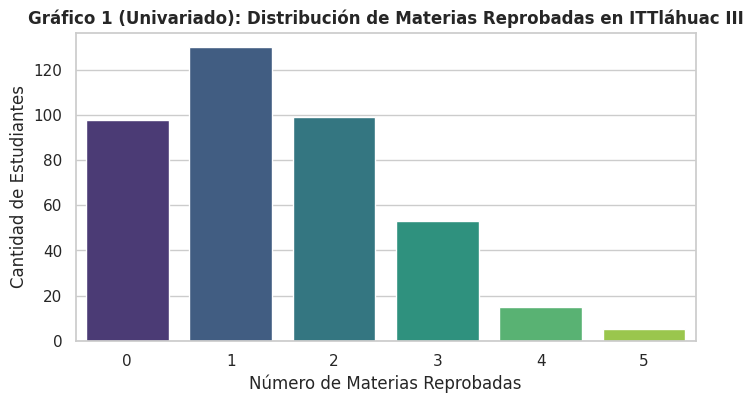

/tmp/ipykernel_1025/218592635.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='desercion', y='promedio_general', palette=['#2b5c8f', '#d95f02'])


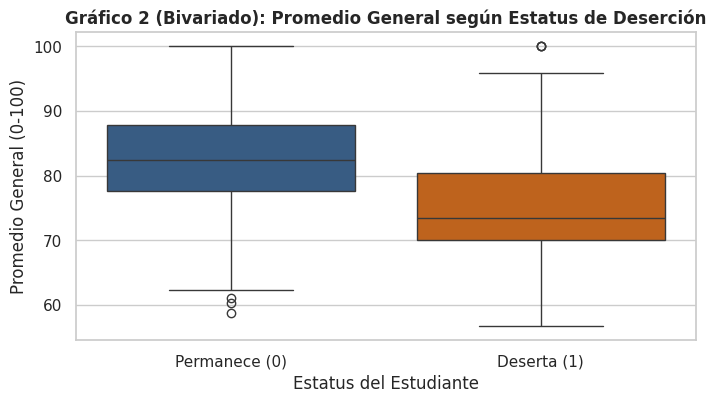

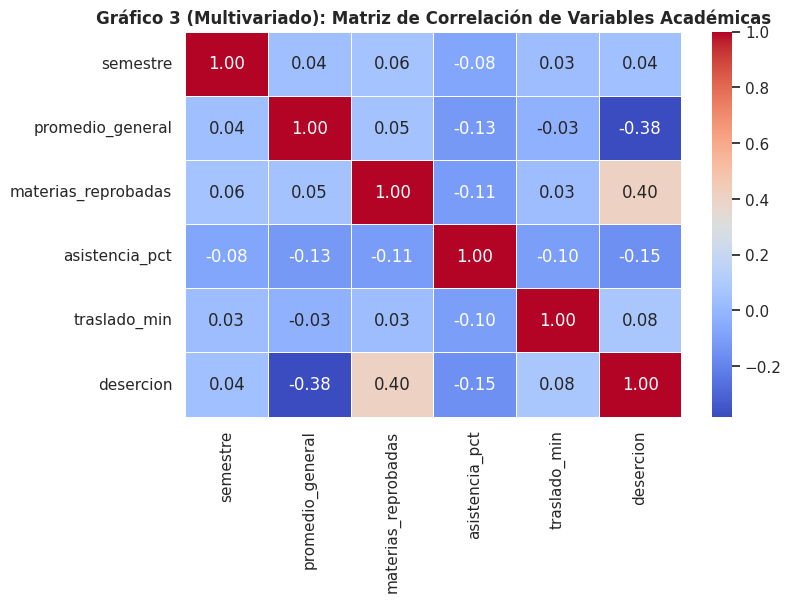

In [3]:
sns.set_theme(style="whitegrid")

# GRÁFICO 1: UNIVARIADO (Distribución de materias reprobadas)
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='materias_reprobadas', palette='viridis')
plt.title('Gráfico 1 (Univariado): Distribución de Materias Reprobadas en ITTláhuac III', fontweight='bold')
plt.xlabel('Número de Materias Reprobadas')
plt.ylabel('Cantidad de Estudiantes')
plt.show()

# GRÁFICO 2: BIVARIADO (Promedio General vs Deserción)
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='desercion', y='promedio_general', palette=['#2b5c8f', '#d95f02'])
plt.title('Gráfico 2 (Bivariado): Promedio General según Estatus de Deserción', fontweight='bold')
plt.xticks([0, 1], ['Permanece (0)', 'Deserta (1)'])
plt.xlabel('Estatus del Estudiante')
plt.ylabel('Promedio General (0-100)')
plt.show()

# GRÁFICO 3: MULTIVARIADO (Mapa de calor de correlaciones)
plt.figure(figsize=(8, 5))
cols_num = ['semestre', 'promedio_general', 'materias_reprobadas', 'asistencia_pct', 'traslado_min', 'desercion']
corr = df[cols_num].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Gráfico 3 (Multivariado): Matriz de Correlación de Variables Académicas', fontweight='bold')
plt.show()

=== MÉTRICAS DEL MODELO (ÁRBOL DE DECISIÓN) ===
Accuracy: 0.9125 (91.25%)
F1-Score: 0.8372

Reporte detallado:
               precision    recall  f1-score   support

           0       0.93      0.95      0.94        58
           1       0.86      0.82      0.84        22

    accuracy                           0.91        80
   macro avg       0.89      0.88      0.89        80
weighted avg       0.91      0.91      0.91        80



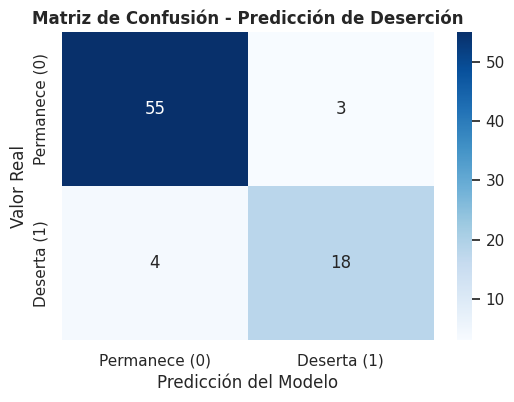

In [4]:
# Codificación de variables categóricas (One-Hot Encoding)
df_model = pd.get_dummies(df.drop(columns=['id_estudiante']), drop_first=True)

X = df_model.drop(columns=['desercion'])
y = df_model['desercion']

# Escalamiento numérico
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# División 80% entrenamiento / 20% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.20, random_state=SEED, stratify=y
)

# Entrenamiento de Árbol de Decisión
modelo = DecisionTreeClassifier(max_depth=4, random_state=SEED)
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)

# Métricas oficiales de clasificación
cm = confusion_matrix(y_test, y_pred)
acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("=== MÉTRICAS DEL MODELO (ÁRBOL DE DECISIÓN) ===")
print(f"Accuracy: {acc:.4f} ({acc*100:.2f}%)")
print(f"F1-Score: {f1:.4f}")
print("\nReporte detallado:\n", classification_report(y_test, y_pred))

# Visualización de Matriz de Confusión
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Permanece (0)', 'Deserta (1)'],
            yticklabels=['Permanece (0)', 'Deserta (1)'])
plt.title('Matriz de Confusión - Predicción de Deserción', fontweight='bold')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real')
plt.show()